Importações, Paleta de Cores e Criando a Variável

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Estilo e Paleta Ética (evita erros de chave em booleanos)
sns.set_theme(style="whitegrid")
COR_ALERT = "#e74c3c"  # Vermelho: Empresa-Mãe testa em animais
COR_SAFE = "#2ecc71"  # Verde: Empresa-Mãe Cruelty-Free

PALETTA_ETICA = {
    False: COR_SAFE,
    True: COR_ALERT,
    "False": COR_SAFE,
    "True": COR_ALERT,
}

VAREJISTAS = ["Ulta", "Sephora", "Beauty_Bay", "Cult_Beauty", "Nordstrom"]

# Variável agregada (Total de Varejistas)
df["total_retailers"] = df[VAREJISTAS].sum(axis=1)

Diagnóstico de Qualidade dos Dados e Resumo Estatístico

In [17]:
print("--- Verificação de Duplicadas e Nulos ---")
print(f"Total de linhas duplicadas: {df.duplicated().sum()}")
print(df.isna().sum())

print("\n--- Resumo Estatístico Inicial ---")
df[VAREJISTAS + ["total_retailers"]].describe().round(3)

--- Verificação de Duplicadas e Nulos ---
Total de linhas duplicadas: 0
Brand                  0
All_vegan              0
Partial_vegan          0
Bad_parent_company     0
Black_owned            0
Ulta                   0
Sephora                0
Beauty_Bay             0
Cult_Beauty            0
Nordstrom              0
total_retailers        0
total_retailers_log    0
dtype: int64

--- Resumo Estatístico Inicial ---


,Ulta,Sephora,Beauty_Bay,Cult_Beauty,Nordstrom,total_retailers
count,922.000,922.0,922.000,922.000,922.000,922.000
mean,0.153,0.1,0.043,0.052,0.055,0.403
std,0.360,0.3,0.204,0.222,0.229,0.865
min,0.000,0.0,0.000,0.000,0.000,0.000
25%,0.000,0.0,0.000,0.000,0.000,0.000
50%,0.000,0.0,0.000,0.000,0.000,0.000
75%,0.000,0.0,0.000,0.000,0.000,0.000
max,1.000,1.0,1.000,1.000,1.000,5.000


Análise de Outliers (IQR) e Transformação Logarítmica

In [18]:
# Cálculo do IQR
q1 = df["total_retailers"].quantile(0.25)
q3 = df["total_retailers"].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
num_outliers = (df["total_retailers"] > limite_superior).sum()

print(f"Limite Superior do IQR: {limite_superior}")
print(f"Número de marcas identificadas como outliers estatísticos: {num_outliers}")

# Transformação Demonstrativa log(1+x)
df["total_retailers_log"] = np.log1p(df["total_retailers"])

comp = pd.DataFrame(
    {
        "Original": [
            df["total_retailers"].mean(),
            df["total_retailers"].median(),
            df["total_retailers"].skew(),
            df["total_retailers"].kurtosis(),
        ],
        "Log(1+x)": [
            df["total_retailers_log"].mean(),
            df["total_retailers_log"].median(),
            df["total_retailers_log"].skew(),
            df["total_retailers_log"].kurtosis(),
        ],
    },
    index=["Média", "Mediana", "Assimetria (Skew)", "Curtose"],
).round(3)

print("\n--- Comparação Antes x Depois da Transformação ---")
print(comp)

Limite Superior do IQR: 0.0
Número de marcas identificadas como outliers estatísticos: 225

--- Comparação Antes x Depois da Transformação ---
                   Original  Log(1+x)
Média                 0.403     0.224
Mediana               0.000     0.000
Assimetria (Skew)     2.646     1.748
Curtose               7.456     1.998


Matriz de Correlação entre Varejistas

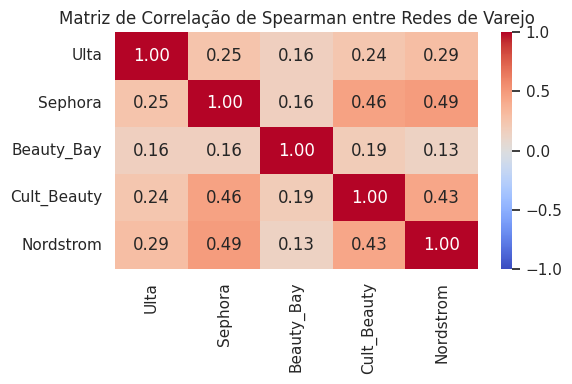

In [19]:
plt.figure(figsize=(6, 4))
sns.heatmap(
    df[VAREJISTAS].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)
plt.title("Matriz de Correlação de Spearman entre Redes de Varejo")
plt.tight_layout()
plt.show()

Varejistas por Empresa-Mãe (Testes em Animais)

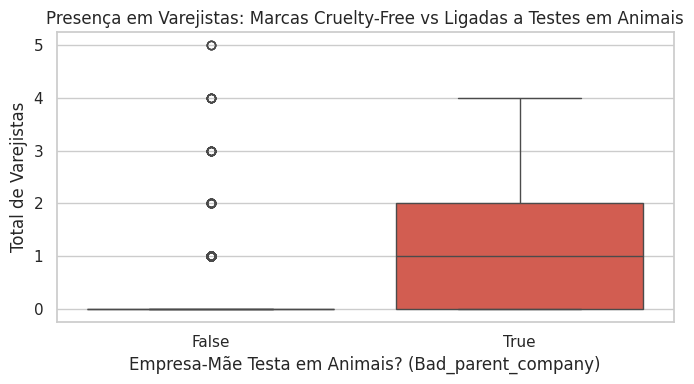

In [20]:
plt.figure(figsize=(7, 4))
sns.boxplot(
    data=df,
    x="Bad_parent_company",
    y="total_retailers",
    hue="Bad_parent_company",
    palette=PALETTA_ETICA,
    legend=False,
)
plt.title(
    "Presença em Varejistas: Marcas Cruelty-Free vs Ligadas a Testes em Animais"
)
plt.xlabel("Empresa-Mãe Testa em Animais? (Bad_parent_company)")
plt.ylabel("Total de Varejistas")
plt.tight_layout()
plt.show()

Cruzamento de Qualitativas (All_vegan x Bad_parent_company)

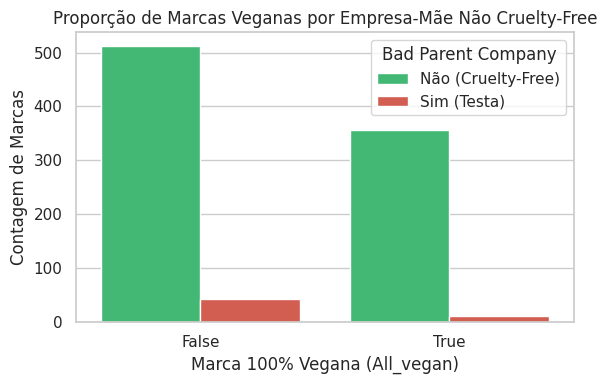

In [21]:
plt.figure(figsize=(6, 4))
sns.countplot(
    data=df, x="All_vegan", hue="Bad_parent_company", palette=PALETTA_ETICA
)
plt.title("Proporção de Marcas Veganas por Empresa-Mãe Não Cruelty-Free")
plt.xlabel("Marca 100% Vegana (All_vegan)")
plt.ylabel("Contagem de Marcas")
plt.legend(
    title="Bad Parent Company", labels=["Não (Cruelty-Free)", "Sim (Testa)"]
)
plt.tight_layout()
plt.show()

6. Princípio Relacional (Análise Bivariada Visual)

Declaração de Uso de IA: A Inteligência Artificial foi utilizada apenas como suporte para organizar os códigos em Python, gerar os gráficos e estruturar os textos de explicação do trabalho.